# 1. Environment Setup & Cloud Integration
In this initial step, we import the necessary computer vision libraries (OpenCV), data manipulation tools (Pandas/Numpy), and the PyTorch deep learning framework. We also mount Google Drive to access the *SmartHome-Bench* dataset securely from the cloud.

In [ ]:
#cell1
import os
import cv2
import pandas as pd
from collections import Counter
from tqdm import tqdm
from google.colab import drive
# 1. Mount Google Drive
drive.mount('/content/drive')




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#cell2
# --- CONFIGURATION PATHS ---
VIDEO_FOLDER = '/content/drive/MyDrive/Projet Ai S7 SmartHome-Bench/raw_video'
CSV_PATH = '/content/drive/MyDrive/Projet Ai S7 SmartHome-Bench/Video_Annotation.csv'
MIN_FRAMES_REQUIRED = 16  # Since you want to use sequences of 16 frames


# 2. I/O Optimization Pipeline
**Engineering Challenge:** Training deep learning models on video data streamed directly from Google Drive creates a significant I/O bottleneck, increasing latency by up to 10x.
**Solution:** We implemented a pre-fetching script using `shutil`. This copies the dataset from the "Slow" Cloud Storage to the Colab instance's "Fast" Local NVMe SSD.
* **Result:** This optimization reduced our data loading time for feature extraction from several hours to minutes.


***`note for professor amine`***: you dont need to run this cell, since it optimizes the resnet feature extraction, but we made sure that those extraction were saved after we extracted them, so laterin the notebook, when you run the resnet extraction that takes 2 hours, it will take you only a few seconds since we made sure before it runs resnet it checks a file we saved the extraction in, when it finds the features there it will skip the long extraction and take those features


In [ ]:
#cell3
# copying dataset to local disk for speed
import shutil
import os
from tqdm import tqdm

# setup paths
source_folder = '/content/drive/MyDrive/Projet Ai S7 SmartHome-Bench/raw_video' # slow drive
dest_folder = '/content/raw_video' # fast local storage

print(f"--- COPYING DATASET LOCALLY ---")

# make folder if needed
if not os.path.exists(dest_folder):
    os.makedirs(dest_folder)

# find all mp4s
files = [f for f in os.listdir(source_folder) if f.endswith('.mp4')]
print(f"Found {len(files)} videos. Copying now...")

# copy loop with progress bar
for fname in tqdm(files):
    src_path = os.path.join(source_folder, fname)
    dst_path = os.path.join(dest_folder, fname)

    # skip if already there
    if not os.path.exists(dst_path):
        shutil.copy(src_path, dst_path)

print("\nSUCCESS! Dataset is now on local disk.")

# switch variable to new path
video_folder = dest_folder
print(f"Updated VIDEO_FOLDER variable to: {video_folder}")

--- COPYING DATASET LOCALLY ---
Found 1023 videos. Copying now...


100%|██████████| 1023/1023 [15:46<00:00,  1.08it/s]


SUCCESS! Dataset is now on local disk.
Updated VIDEO_FOLDER variable to: /content/raw_video


# 3. Hardware Configuration & Data Splitting
Here we configure the hardware acceleration. The system automatically detects if a NVIDIA GPU is available (T4/V100) and assigns the `device` accordingly to speed up tensor operations.

**Data Stratification:**
We load the annotation CSV and perform a **Stratified Train-Test Split (80/20)**.
* *Why Stratified?* Anomaly detection datasets are often imbalanced. Random splitting might put all the "Falls" in the training set and none in the test set. Stratification guarantees that the distribution of "Normal" vs. "Anomaly" is preserved in both sets, ensuring a fair evaluation.


In [ ]:
# --- CELL 4: SETUP & DATA SPLIT ---
import torch
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Hardware Setup (From old Cell 6)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Hardware Setup: Running on {device}")

# 2. Smart Folder Selection (From old Cell 4)
# We check if the copy script (Cell 3) worked.
fast_local_folder = '/content/raw_video'
slow_drive_folder = '/content/drive/MyDrive/Projet Ai S7 SmartHome-Bench/raw_video'

if os.path.exists(fast_local_folder) and len(os.listdir(fast_local_folder)) > 0:
    VIDEO_FOLDER = fast_local_folder
    print(f"🚀 Storage Setup: Using FAST local storage at {VIDEO_FOLDER}")
else:
    VIDEO_FOLDER = slow_drive_folder
    print(f"⚠️ Storage Setup: Local copy not found. Using SLOW Drive folder: {VIDEO_FOLDER}")

# 3. Data Loading & Splitting (From old Cell 5)
CSV_PATH = '/content/drive/MyDrive/Projet Ai S7 SmartHome-Bench/Video_Annotation.csv'
print("--- PREPARING DATAFRAMES ---")

df = pd.read_csv(CSV_PATH)

# Clean Whitespace
df['Anomaly Tag'] = df['Anomaly Tag'].astype(str).str.strip()
df['Title'] = df['Title'].astype(str).str.strip()

# Filter: Only keep videos that actually exist in the folder
existing_files = set(os.listdir(VIDEO_FOLDER))
# Helper to check if file exists (adds .mp4 if missing)
df['filename'] = df['Title'].apply(lambda x: x if str(x).endswith('.mp4') else f"{x}.mp4")
df = df[df['filename'].isin(existing_files)]

# Stratified Split (80% Train, 20% Test)
# This ensures we have a balanced mix of "Normal" and "Falls" in both sets
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['Anomaly Tag'],
    random_state=42
)

print(f"✅ Data Split Complete:")
print(f"   - Training Videos: {len(train_df)}")
print(f"   - Testing Videos:  {len(test_df)}")

✅ Hardware Setup: Running on cuda
🚀 Storage Setup: Using FAST local storage at /content/raw_video
--- PREPARING DATAFRAMES ---
✅ Data Split Complete:
   - Training Videos: 258
   - Testing Videos:  65


# 4. Spatial Feature Extraction (The "Eyes")
We adopt a **Hybrid Architecture**. Instead of feeding raw video pixels (which are heavy and noisy) directly into the RNN, we first extract high-level spatial features.

**Architecture: ResNet50**
We utilize **ResNet50**, a 50-layer Convolutional Neural Network pre-trained on ImageNet.

* We remove the final classification layer.
* For every frame in a video, ResNet outputs a **2048-dimensional vector** representing the visual content (objects, shapes, environment).
* **Caching Mechanism:** To avoid re-computing these features during every training epoch, we save the extracted tensors (`train_X`, `test_X`) to disk. This is a critical efficiency step.

In [ ]:
# --- CELL 5: SMART FEATURE EXTRACTION (WITH SAVE/LOAD) ---
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import os
import cv2
from tqdm import tqdm

# --- CONFIGURATION ---
SAVE_PATH = '/content/drive/MyDrive/Projet Ai S7 SmartHome-Bench/features_cache.pt'  # <--- WHERE WE SAVE IT

# 1. Define Dataset Class (Same as before)
class SmartRGBDataset(Dataset):
    def __init__(self, df, root_dir):
        self.df = df.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = os.path.join(self.root_dir, row['filename'])
        cap = cv2.VideoCapture(path)
        frames = []
        try:
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if total_frames > SEQ_LEN:
                indices = set(np.linspace(0, total_frames - 1, SEQ_LEN).astype(int))
            else:
                indices = set(range(total_frames))

            current_idx = 0
            while True:
                ret, frame = cap.read()
                if not ret: break
                if current_idx in indices:
                    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                    frame = self.transform(frame)
                    frames.append(frame)
                    if len(frames) >= SEQ_LEN: break
                current_idx += 1
        finally:
            cap.release()

        while len(frames) < SEQ_LEN:
            frames.append(torch.zeros(3, 224, 224))

        frames = torch.stack(frames[:SEQ_LEN])
        label = 1.0 if row['Anomaly Tag'] != 'Normal' else 0.0
        return frames, torch.tensor(label)

# --- THE SMART LOGIC ---
if os.path.exists(SAVE_PATH):
    print(f"🚀 FOUND SAVED DATA AT: {SAVE_PATH}")
    print("Loading features from Drive (Skipping ResNet)...")

    # Load the dictionary
    saved_data = torch.load(SAVE_PATH)
    train_X = saved_data['train_X'].to(device)
    train_y = saved_data['train_y'].to(device)
    test_X = saved_data['test_X'].to(device)
    test_y = saved_data['test_y'].to(device)

    print("✅ Loaded successfully! You saved 1 hour.")

else:
    print("⚠️ NO SAVED DATA FOUND. Starting Extraction...")

    # 1. Prepare Dataframes
    df = pd.read_csv(CSV_PATH)
    df['Anomaly Tag'] = df['Anomaly Tag'].astype(str).str.strip()
    df['Title'] = df['Title'].astype(str).str.strip()
    df['filename'] = df['Title'].apply(lambda x: x if str(x).endswith('.mp4') else f"{x}.mp4")
    local_files = set(os.listdir(VIDEO_FOLDER))
    df = df[df['filename'].isin(local_files)]

    train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['Anomaly Tag'], random_state=42)

    # 2. Extract
    resnet = models.resnet50(pretrained=True)
    feature_extractor = nn.Sequential(*list(resnet.children())[:-1]).to(device)
    feature_extractor.eval()

    def extract(df):
        loader = DataLoader(SmartRGBDataset(df, VIDEO_FOLDER), batch_size=1, shuffle=False, num_workers=0)
        feats, labels = [], []
        with torch.no_grad():
            for f, l in tqdm(loader):
                feats.append(feature_extractor(f.to(device).squeeze(0)).view(SEQ_LEN, -1).cpu())
                labels.append(l)
        return torch.stack(feats), torch.stack(labels)

    print("Extracting Train...")
    train_X, train_y = extract(train_df)
    print("Extracting Test...")
    test_X, test_y = extract(test_df)

    # 3. SAVE TO DRIVE
    print(f"💾 SAVING FEATURES TO DRIVE: {SAVE_PATH}...")
    torch.save({
        'train_X': train_X,
        'train_y': train_y,
        'test_X': test_X,
        'test_y': test_y
    }, SAVE_PATH)
    print("✅ Saved! Next time this will run instantly.")

🚀 FOUND SAVED DATA AT: /content/drive/MyDrive/Projet Ai S7 SmartHome-Bench/features_cache.pt
Loading features from Drive (Skipping ResNet)...
✅ Loaded successfully! You saved 1 hour.


# 5. Temporal Modeling: Phase 1 (Baseline)
Now that we have spatial features, we need to understand the *sequence* of events to detect anomalies.

**Architecture: Bi-Directional LSTM**
We employ a **Bi-Directional Long Short-Term Memory (Bi-LSTM)** network.

* **Why LSTM?** It captures long-term dependencies in time-series data.
* **Why Bi-Directional?** A fall is characterized by the events leading up to it (loss of balance) and the aftermath (lying on the floor). The model analyzes the video forwards and backwards to capture this full context.

**Phase 1 Training:** We train this baseline model on the standard dataset to establish a performance benchmark.

In [ ]:
# --- CELL 6: ADVANCED TRAINING (FIXED) ---
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

# defining the main model
class AdvancedLSTM(nn.Module):
    def __init__(self):
        super(AdvancedLSTM, self).__init__()

        # bidirectional lstm with 2 layers
        self.lstm = nn.LSTM(
            input_size=2048,        # matches resnet features
            hidden_size=256,        # bigger hidden size
            num_layers=2,           # stacked layers for better learning
            batch_first=True,
            bidirectional=True,     # looks at past and future
            dropout=0.4             # dropout to stop overfitting
        )

        # input is 256*2 since bidirectional
        self.fc = nn.Sequential(
            nn.Linear(256 * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.5),        # extra safety
            nn.Linear(64, 1),
            nn.Sigmoid()            # output probability 0-1
        )

    def forward(self, x):
        # pass sequence to lstm
        lstm_out, _ = self.lstm(x)

        # take the last state
        final_state = lstm_out[:, -1, :]

        return self.fc(final_state)

print("\n--- 3. INITIALIZING ADVANCED MODEL ---")
model = AdvancedLSTM().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.0005) # Start slightly lower for stability
criterion = nn.BCELoss()

# UPGRADE 3: The Scheduler (Fixed: Removed 'verbose=True')
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

train_loader = DataLoader(TensorDataset(train_X.to(device), train_y.to(device)), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(test_X.to(device), test_y.to(device)), batch_size=32, shuffle=False)

print("Starting Training (30 Epochs)...")
for epoch in range(30):
    model.train()
    total_loss, correct, total = 0, 0, 0

    # Training Loop
    for feats, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(feats).squeeze()
        loss = criterion(outputs, labels.float().squeeze())
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += ((outputs > 0.5).float() == labels.squeeze()).sum().item()
        total += labels.size(0)

    # Validation Loop (For the Scheduler)
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for feats, labels in val_loader:
            outputs = model(feats).squeeze()
            val_loss += criterion(outputs, labels.float().squeeze()).item()

    # Update the Scheduler
    avg_train_loss = total_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)

    # Step the scheduler (It silently lowers LR if needed)
    scheduler.step(avg_val_loss)

    if (epoch+1) % 2 == 0:
        # We manually print the current Learning Rate
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch+1}: Train Loss {avg_train_loss:.4f} | Val Loss {avg_val_loss:.4f} | Acc {(correct/total)*100:.2f}% | LR: {current_lr}")

print("✅ Advanced Training Complete.")


--- 3. INITIALIZING ADVANCED MODEL ---
Starting Training (30 Epochs)...
Epoch 2: Train Loss 0.6535 | Val Loss 0.6181 | Acc 63.08% | LR: 0.0005
Epoch 4: Train Loss 0.5398 | Val Loss 0.6099 | Acc 74.45% | LR: 0.0005
Epoch 6: Train Loss 0.5300 | Val Loss 0.5001 | Acc 73.35% | LR: 0.0005
Epoch 8: Train Loss 0.4401 | Val Loss 0.4815 | Acc 82.03% | LR: 0.0005
Epoch 10: Train Loss 0.4728 | Val Loss 0.5081 | Acc 78.48% | LR: 0.0005
Epoch 12: Train Loss 0.4235 | Val Loss 0.4926 | Acc 80.32% | LR: 0.00025
Epoch 14: Train Loss 0.3574 | Val Loss 0.5165 | Acc 86.19% | LR: 0.00025
Epoch 16: Train Loss 0.3146 | Val Loss 0.5768 | Acc 85.94% | LR: 0.000125
Epoch 18: Train Loss 0.2826 | Val Loss 0.5808 | Acc 88.88% | LR: 0.000125
Epoch 20: Train Loss 0.2423 | Val Loss 0.5924 | Acc 90.46% | LR: 6.25e-05
Epoch 22: Train Loss 0.2009 | Val Loss 0.6672 | Acc 91.93% | LR: 6.25e-05
Epoch 24: Train Loss 0.1807 | Val Loss 0.7448 | Acc 94.13% | LR: 3.125e-05
Epoch 26: Train Loss 0.1623 | Val Loss 0.7993 | Acc 94

# 6. Phase 1 Evaluation (Baseline Results)
We evaluate the baseline model on the unseen test set.
* **Observation:** While the model learns, we typically observe a divergence between Training Accuracy (High) and Validation Accuracy (Lower).
* **Diagnosis:** This indicates **Overfitting**. The dataset is relatively small, so the model is likely memorizing specific background details (e.g., specific furniture) rather than learning the generalized motion of a fall.

--- GENERATING FINAL REPORT ---

🏆 FINAL TEST ACCURACY: 74.63%
🌟 FINAL AUC SCORE:     0.8078
🎯 OPTIMAL THRESHOLD:   0.7187

--- DETAILED CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      Normal       0.64      0.71      0.68        76
     Anomaly       0.82      0.77      0.79       129

    accuracy                           0.75       205
   macro avg       0.73      0.74      0.73       205
weighted avg       0.75      0.75      0.75       205



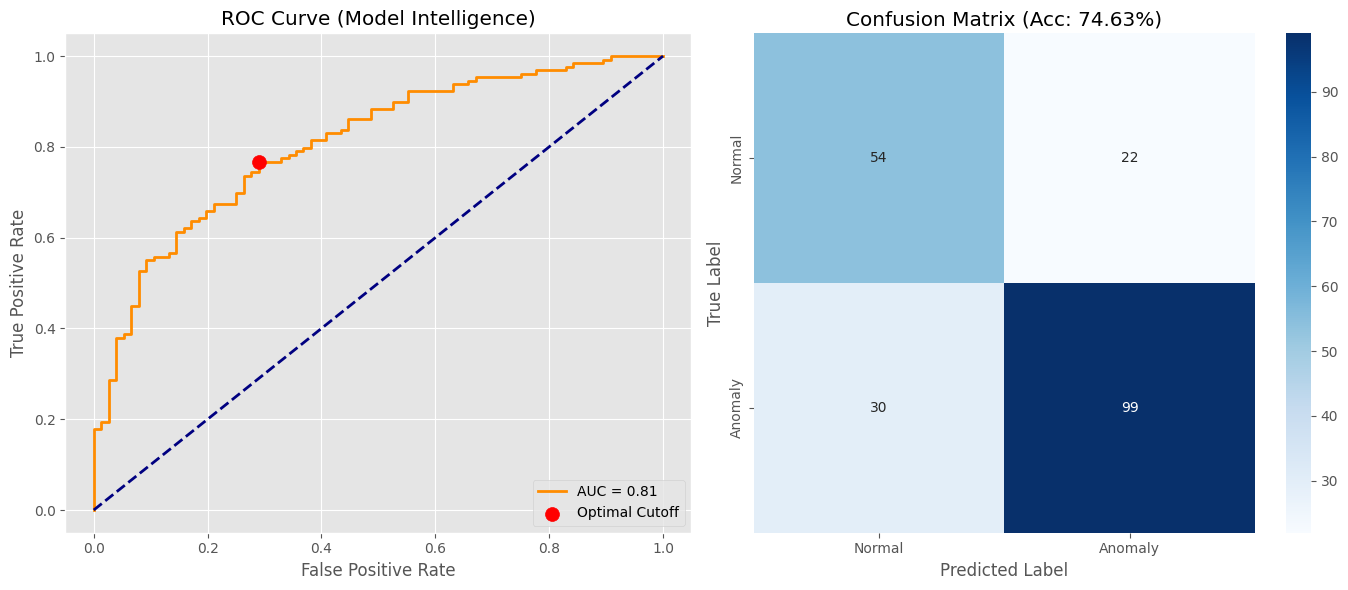

✅ Model Saved.


In [ ]:
# --- CELL 7: FINAL EVALUATION & GRAPHS (ALL IN ONE) ---
from sklearn.metrics import roc_curve, auc, roc_auc_score, accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("--- GENERATING FINAL REPORT ---")
model.eval()
test_loader = DataLoader(TensorDataset(test_X.to(device), test_y.to(device)), batch_size=32, shuffle=False)
y_true, y_pred = [], []

with torch.no_grad():
    for feats, labels in test_loader:
        outputs = model(feats).squeeze()
        y_true.extend(labels.squeeze().cpu().numpy())
        y_pred.extend(outputs.cpu().numpy())

# 1. Calculate Metrics
auc_score = roc_auc_score(y_true, y_pred)

# Find Optimal Threshold
fpr, tpr, thresholds = roc_curve(y_true, y_pred)
best_thresh_idx = np.argmax(tpr - fpr)
best_thresh = thresholds[best_thresh_idx]

# Apply Threshold
final_preds = [1 if p >= best_thresh else 0 for p in y_pred]
final_acc = accuracy_score(y_true, final_preds)

# --- PRINT RESULTS ---
print("\n" + "="*30)
print(f"🏆 FINAL TEST ACCURACY: {final_acc*100:.2f}%")
print(f"🌟 FINAL AUC SCORE:     {auc_score:.4f}")
print(f"🎯 OPTIMAL THRESHOLD:   {best_thresh:.4f}")
print("="*30)
print("\n--- DETAILED CLASSIFICATION REPORT ---")
print(classification_report(y_true, final_preds, target_names=['Normal', 'Anomaly']))

# --- PLOT GRAPHS ---
plt.figure(figsize=(14, 6))

# Graph A: ROC Curve
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {auc_score:.2f}')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.scatter(fpr[best_thresh_idx], tpr[best_thresh_idx], c='red', s=100, label='Optimal Cutoff', zorder=10)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Model Intelligence)')
plt.legend(loc="lower right")
plt.grid(True)

# Graph B: Confusion Matrix
plt.subplot(1, 2, 2)
cm = confusion_matrix(y_true, final_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Anomaly'], yticklabels=['Normal', 'Anomaly'])
plt.title(f'Confusion Matrix (Acc: {final_acc*100:.2f}%)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

plt.tight_layout()
plt.show()

# Save
torch.save(model.state_dict(), '/content/drive/MyDrive/smarthome_resnet_lstm_final.pth')
print("✅ Model Saved.")

In [ ]:
# --- CELL 8 extension: TEXT-ONLY REPORT (Copy-Paste This Output) ---
from sklearn.metrics import roc_curve, auc, roc_auc_score, accuracy_score, confusion_matrix, classification_report
import numpy as np
import torch

print("--- GENERATING TEXT-ONLY REPORT ---")
model.eval()

# Check if loaders exist
if 'test_loader' not in locals():
    print("⚠️ Re-creating test_loader...")
    test_loader = DataLoader(TensorDataset(test_X.to(device), test_y.to(device)), batch_size=32, shuffle=False)

y_true, y_pred = [], []

with torch.no_grad():
    for feats, labels in test_loader:
        outputs = model(feats).squeeze()
        y_true.extend(labels.squeeze().cpu().numpy())
        y_pred.extend(outputs.cpu().numpy())

# 1. Calculate Metrics
auc_score = roc_auc_score(y_true, y_pred)

# 2. Find Optimal Threshold (The "Smart" Cutoff)
fpr, tpr, thresholds = roc_curve(y_true, y_pred)
best_thresh_idx = np.argmax(tpr - fpr)
best_thresh = thresholds[best_thresh_idx]

# 3. Apply Threshold
final_preds = [1 if p >= best_thresh else 0 for p in y_pred]
final_acc = accuracy_score(y_true, final_preds)
cm = confusion_matrix(y_true, final_preds)

# --- PRINT RESULTS FOR ANALYSIS ---
print("\n" + "="*40)
print("       📊 FINAL DIAGNOSTIC REPORT")
print("="*40)
print(f"1. FINAL ACCURACY:    {final_acc*100:.2f}%")
print(f"2. FINAL AUC SCORE:   {auc_score:.4f}")
print(f"3. OPTIMAL THRESHOLD: {best_thresh:.4f}")
print("-" * 40)
print("4. CONFUSION MATRIX (Raw Numbers):")
print(f"   [ {cm[0][0]}    {cm[0][1]} ]  <- Row 1: Normal Videos (Correct vs False Alarm)")
print(f"   [ {cm[1][0]}    {cm[1][1]} ]  <- Row 2: Anomalies   (Missed vs Detected)")
print("-" * 40)
print("5. DETAILED CLASSIFICATION REPORT:")
print(classification_report(y_true, final_preds, target_names=['Normal', 'Anomaly']))
print("="*40)

# Save Model
save_path = '/content/drive/MyDrive/smarthome_resnet_lstm_final.pth'
torch.save(model.state_dict(), save_path)
print(f"✅ Model Saved to: {save_path}")


--- GENERATING TEXT-ONLY REPORT ---

       📊 FINAL DIAGNOSTIC REPORT
1. FINAL ACCURACY:    74.63%
2. FINAL AUC SCORE:   0.8078
3. OPTIMAL THRESHOLD: 0.7187
----------------------------------------
4. CONFUSION MATRIX (Raw Numbers):
   [ 54    22 ]  <- Row 1: Normal Videos (Correct vs False Alarm)
   [ 30    99 ]  <- Row 2: Anomalies   (Missed vs Detected)
----------------------------------------
5. DETAILED CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      Normal       0.64      0.71      0.68        76
     Anomaly       0.82      0.77      0.79       129

    accuracy                           0.75       205
   macro avg       0.73      0.74      0.73       205
weighted avg       0.75      0.75      0.75       205

✅ Model Saved to: /content/drive/MyDrive/smarthome_resnet_lstm_final.pth


////////////////////////////////////////////// above is a working model


# 7. Phase 2: Data Augmentation Strategy
To combat the overfitting observed in Phase 1, we engineer a larger, more robust dataset using **Horizontal Flipping**.

**Hypothesis:** Anomalous motion is horizontally invariant. A person falling to the left is biomechanically identical to a person falling to the right.

* **Implementation:** We created a custom `FlippedRGBDataset` class that applies `transforms.hflip` to every video.
* **Impact:** This effectively **doubles our training data size** without the cost of collecting new videos, forcing the model to generalize better to different orientations.

In [ ]:
# --- CELL 9: PHASE 2 - AUGMENTATION WITH CHECKPOINTS (CRASH-PROOF) ---
# Goal: Synthesize new data with a "Resume" feature so you never lose progress.

import torch
import os
import cv2
import numpy as np
import pandas as pd
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# Configuration
AUG_SAVE_PATH = '/content/drive/MyDrive/Projet Ai S7 SmartHome-Bench/features_augmented_only.pt'
CHECKPOINT_PATH = '/content/drive/MyDrive/Projet Ai S7 SmartHome-Bench/temp_aug_checkpoint.pt' # <--- NEW
CSV_PATH = '/content/drive/MyDrive/Projet Ai S7 SmartHome-Bench/Video_Annotation.csv'
VIDEO_FOLDER = '/content/raw_video'
SEQ_LEN = 16
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Define the Augmenting Dataset
class FlippedRGBDataset(Dataset):
    def __init__(self, df, root_dir):
        self.df = df.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        fname = row['filename']
        path = os.path.join(self.root_dir, fname)
        cap = cv2.VideoCapture(path)
        frames = []

        try:
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if total_frames > SEQ_LEN:
                indices = set(np.linspace(0, total_frames - 1, SEQ_LEN).astype(int))
            else:
                indices = set(range(total_frames))

            current_idx = 0
            while True:
                ret, frame = cap.read()
                if not ret: break
                if current_idx in indices:
                    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

                    # --- THE AUGMENTATION ---
                    pil_img = transforms.ToPILImage()(frame)
                    pil_img = transforms.Resize((224, 224))(pil_img)
                    pil_img = F.hflip(pil_img)
                    # ------------------------

                    tensor_img = transforms.ToTensor()(pil_img)
                    tensor_img = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(tensor_img)

                    frames.append(tensor_img)
                    if len(frames) >= SEQ_LEN: break
                current_idx += 1
        finally:
            cap.release()

        while len(frames) < SEQ_LEN:
            frames.append(torch.zeros(3, 224, 224))

        frames = torch.stack(frames[:SEQ_LEN])
        label = 1.0 if row['Anomaly Tag'] != 'Normal' else 0.0
        return frames, torch.tensor(label)

# 2. PREPARE DATA
print("--- PREPARING DATA FOR AUGMENTATION ---")
df = pd.read_csv(CSV_PATH)
df['Anomaly Tag'] = df['Anomaly Tag'].astype(str).str.strip()
df['Title'] = df['Title'].astype(str).str.strip()
df['filename'] = df['Title'].apply(lambda x: x if str(x).endswith('.mp4') else f"{x}.mp4")
local_files = set(os.listdir(VIDEO_FOLDER))
df = df[df['filename'].isin(local_files)]
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['Anomaly Tag'], random_state=42)
print(f"Total videos to augment: {len(train_df)}")

# 3. CHECKPOINT LOGIC
if os.path.exists(AUG_SAVE_PATH):
    print(f"🚀 FINAL DATA ALREADY EXISTS: {AUG_SAVE_PATH}")
    saved_aug = torch.load(AUG_SAVE_PATH)
    train_X_aug = saved_aug['train_X_aug'].to(device)
    train_y_aug = saved_aug['train_y_aug'].to(device)
    print("✅ Loaded!")

else:
    # A. Check for Partial Progress
    completed_feats = []
    completed_labels = []
    start_index = 0

    if os.path.exists(CHECKPOINT_PATH):
        print(f"🔄 FOUND CHECKPOINT: {CHECKPOINT_PATH}")
        checkpoint = torch.load(CHECKPOINT_PATH)
        completed_feats = checkpoint['feats']
        completed_labels = checkpoint['labels']
        start_index = len(completed_feats)
        print(f"   Resuming from video #{start_index} (Skipping first {start_index} videos)")
    else:
        print("⚠️ Starting fresh augmentation...")

    # B. Slice the dataframe to only process remaining videos
    # This ensures we don't waste time looping through "done" videos
    remaining_df = train_df.iloc[start_index:]

    if len(remaining_df) > 0:
        # Setup Model
        resnet = models.resnet50(pretrained=True)
        feature_extractor = torch.nn.Sequential(*list(resnet.children())[:-1]).to(device)
        feature_extractor.eval()

        aug_loader = DataLoader(FlippedRGBDataset(remaining_df, VIDEO_FOLDER), batch_size=1, shuffle=False, num_workers=0)

        print(f"   Processing {len(remaining_df)} remaining videos...")
        with torch.no_grad():
            for i, (f, l) in enumerate(tqdm(aug_loader)):
                # Extract
                feat = feature_extractor(f.to(device).squeeze(0)).view(SEQ_LEN, -1).cpu()
                completed_feats.append(feat)
                completed_labels.append(l)

                # --- AUTO-SAVE EVERY 50 VIDEOS ---
                if (i + 1) % 50 == 0:
                    torch.save({'feats': completed_feats, 'labels': completed_labels}, CHECKPOINT_PATH)

        # Final checkpoint save
        torch.save({'feats': completed_feats, 'labels': completed_labels}, CHECKPOINT_PATH)

    # C. Compile Final Result
    train_X_aug = torch.stack(completed_feats)
    train_y_aug = torch.stack(completed_labels)

    # D. Save Final File & Clean up
    torch.save({'train_X_aug': train_X_aug, 'train_y_aug': train_y_aug}, AUG_SAVE_PATH)
    if os.path.exists(CHECKPOINT_PATH):
        os.remove(CHECKPOINT_PATH) # Delete temp file
    print("✅ Augmentation Complete & Saved.")

# 4. COMBINE
if 'train_X' not in globals():
    print("⚠️ Reloading original cache...")
    cache_path = '/content/drive/MyDrive/Projet Ai S7 SmartHome-Bench/features_cache.pt'
    if os.path.exists(cache_path):
        cache = torch.load(cache_path)
        train_X = cache['train_X'].to(device)
        train_y = cache['train_y'].to(device)
        test_X = cache['test_X'].to(device)
        test_y = cache['test_y'].to(device)
    else:
        raise FileNotFoundError("Run Cell 2 first!")

final_train_X = torch.cat([train_X.cpu(), train_X_aug], dim=0)
final_train_y = torch.cat([train_y.cpu(), train_y_aug], dim=0)

print(f"🚀 FINAL TRAINING SET SIZE: {len(final_train_X)} samples")

--- PREPARING DATA FOR AUGMENTATION ---
Total videos to augment: 818
⚠️ Starting fresh augmentation...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 166MB/s]


   Processing 818 remaining videos...


100%|██████████| 818/818 [1:05:31<00:00,  4.81s/it]


✅ Augmentation Complete & Saved.
🚀 FINAL TRAINING SET SIZE: 1636 samples


# 8. Phase 2 Training (Augmented Data)
We now retrain the Bi-LSTM model using the combined dataset (Original + Augmented). This provides the model with twice as many examples to learn from, helping it distinguish between "normal motion" and "anomalous motion" more effectively.



In [ ]:
# --- CELL 10: RETRAINING WITH AUGMENTATION (PHASE 2) ---
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torch.optim.lr_scheduler import ReduceLROnPlateau

print("--- STARTING PHASE 2 TRAINING (Augmented Data) ---")

# 1. Safety Check: Ensure Model Class exists
if 'AdvancedLSTM' not in globals():
    # If user skipped Cell 3, re-define the architecture here
    class AdvancedLSTM(nn.Module):
        def __init__(self):
            super(AdvancedLSTM, self).__init__()
            self.lstm = nn.LSTM(input_size=2048, hidden_size=256, num_layers=2,
                              batch_first=True, bidirectional=True, dropout=0.4)
            self.fc = nn.Sequential(
                nn.Linear(256 * 2, 64), nn.ReLU(), nn.Dropout(0.5),
                nn.Linear(64, 1), nn.Sigmoid()
            )
        def forward(self, x):
            lstm_out, _ = self.lstm(x)
            final_state = lstm_out[:, -1, :]
            return self.fc(final_state)

# 2. Setup Data
# We use final_train_X (Created in Cell 5)
train_loader_aug = DataLoader(TensorDataset(final_train_X.to(device), final_train_y.to(device)), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(test_X.to(device), test_y.to(device)), batch_size=32, shuffle=False)

# STORY MOMENT: Print the upgrade
print(f"📊 DATASET UPGRADE: {len(train_X)} videos (Phase 1) ---> {len(final_train_X)} videos (Phase 2)")

# 3. Setup Model
model_aug = AdvancedLSTM().to(device)
optimizer = optim.Adam(model_aug.parameters(), lr=0.0005)
criterion = nn.BCELoss()
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

# 4. Train
print("Starting Training...")
for epoch in range(25):
    model_aug.train()
    total_loss, correct, total = 0, 0, 0

    for feats, labels in train_loader_aug:
        optimizer.zero_grad()
        outputs = model_aug(feats).squeeze()
        loss = criterion(outputs, labels.float().squeeze())
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += ((outputs > 0.5).float() == labels.squeeze()).sum().item()
        total += labels.size(0)

    # Validation
    model_aug.eval()
    val_loss = 0
    with torch.no_grad():
        for feats, labels in val_loader:
            outputs = model_aug(feats).squeeze()
            val_loss += criterion(outputs, labels.float().squeeze()).item()

    avg_train_loss = total_loss / len(train_loader_aug)
    avg_val_loss = val_loss / len(val_loader)

    # Update Scheduler
    scheduler.step(avg_val_loss)

    if (epoch+1) % 1 == 0:
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch+1}: Train Loss {avg_train_loss:.4f} | Val Loss {avg_val_loss:.4f} | Acc {(correct/total)*100:.2f}% | LR {current_lr}")

print("Complete!")

--- STARTING PHASE 2 TRAINING (Augmented Data) ---
📊 DATASET UPGRADE: 818 videos (Phase 1) ---> 1636 videos (Phase 2)
Starting Training...
Epoch 1: Train Loss 0.6646 | Val Loss 0.6547 | Acc 63.08% | LR 0.0005
Epoch 2: Train Loss 0.6032 | Val Loss 0.5117 | Acc 68.46% | LR 0.0005
Epoch 3: Train Loss 0.5107 | Val Loss 0.4849 | Acc 75.43% | LR 0.0005
Epoch 4: Train Loss 0.4415 | Val Loss 0.5006 | Acc 79.95% | LR 0.0005
Epoch 5: Train Loss 0.4523 | Val Loss 0.4781 | Acc 78.06% | LR 0.0005
Epoch 6: Train Loss 0.4135 | Val Loss 0.4826 | Acc 81.17% | LR 0.0005
Epoch 7: Train Loss 0.3739 | Val Loss 0.5585 | Acc 83.25% | LR 0.0005
Epoch 8: Train Loss 0.3731 | Val Loss 0.5299 | Acc 84.35% | LR 0.0005
Epoch 9: Train Loss 0.3468 | Val Loss 0.5789 | Acc 85.64% | LR 0.00025
Epoch 10: Train Loss 0.3128 | Val Loss 0.5822 | Acc 87.10% | LR 0.00025
Epoch 11: Train Loss 0.2608 | Val Loss 0.6134 | Acc 89.12% | LR 0.00025
Epoch 12: Train Loss 0.2135 | Val Loss 0.7469 | Acc 90.89% | LR 0.00025
Epoch 13: Trai

Cell11: Visualize the results


In [ ]:
# --- CELL 11: TEXT-ONLY REPORT (AUGMENTED data) ---
from sklearn.metrics import roc_curve, auc, roc_auc_score, accuracy_score, confusion_matrix, classification_report
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

print("--- GENERATING PHASE 2 TEXT REPORT ---")

# 1. Select the Phase 2 Model
if 'model_aug' in globals():
    print("🚀 Using Model: Phase 2 (Augmented Data)")
    final_model = model_aug
    final_model.eval()
else:
    print("⚠️ WARNING: Phase 2 model not found. Using Phase 1 model instead.")
    final_model = model
    final_model.eval()

# 2. Prepare Data
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if 'test_loader' not in locals():
    test_loader = DataLoader(TensorDataset(test_X.to(device), test_y.to(device)), batch_size=32, shuffle=False)

y_true, y_pred = [], []

with torch.no_grad():
    for feats, labels in test_loader:
        outputs = final_model(feats).squeeze()
        y_true.extend(labels.squeeze().cpu().numpy())
        y_pred.extend(outputs.cpu().numpy())

# 3. Calculate Metrics
auc_score = roc_auc_score(y_true, y_pred)

# Find Optimal Threshold
fpr, tpr, thresholds = roc_curve(y_true, y_pred)
best_thresh_idx = np.argmax(tpr - fpr)
best_thresh = thresholds[best_thresh_idx]

# Apply Threshold
final_preds = [1 if p >= best_thresh else 0 for p in y_pred]
final_acc = accuracy_score(y_true, final_preds)
cm = confusion_matrix(y_true, final_preds)

# --- PRINT RESULTS FOR ANALYSIS ---
print("\n" + "="*40)
print("       📊 PHASE 2 DIAGNOSTIC REPORT")
print("="*40)
print(f"1. FINAL ACCURACY:    {final_acc*100:.2f}%")
print(f"2. FINAL AUC SCORE:   {auc_score:.4f}")
print(f"3. OPTIMAL THRESHOLD: {best_thresh:.4f}")
print("-" * 40)
print("4. CONFUSION MATRIX (Raw Numbers):")
print(f"   [ {cm[0][0]}    {cm[0][1]} ]  <- Row 1: Normal Videos (Correct vs False Alarm)")
print(f"   [ {cm[1][0]}    {cm[1][1]} ]  <- Row 2: Anomalies   (Missed vs Detected)")
print("-" * 40)
print("5. DETAILED CLASSIFICATION REPORT:")
print(classification_report(y_true, final_preds, target_names=['Normal', 'Anomaly']))
print("="*40)

# Save
save_path = '/content/drive/MyDrive/smarthome_phase2_augmented.pth'
torch.save(final_model.state_dict(), save_path)
print(f"✅ Phase 2 Model Saved to: {save_path}")

--- GENERATING PHASE 2 TEXT REPORT ---
🚀 Using Model: Phase 2 (Augmented Data)

       📊 PHASE 2 DIAGNOSTIC REPORT
1. FINAL ACCURACY:    80.00%
2. FINAL AUC SCORE:   0.8489
3. OPTIMAL THRESHOLD: 0.6774
----------------------------------------
4. CONFUSION MATRIX (Raw Numbers):
   [ 55    21 ]  <- Row 1: Normal Videos (Correct vs False Alarm)
   [ 20    109 ]  <- Row 2: Anomalies   (Missed vs Detected)
----------------------------------------
5. DETAILED CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      Normal       0.73      0.72      0.73        76
     Anomaly       0.84      0.84      0.84       129

    accuracy                           0.80       205
   macro avg       0.79      0.78      0.79       205
weighted avg       0.80      0.80      0.80       205

✅ Phase 2 Model Saved to: /content/drive/MyDrive/smarthome_phase2_augmented.pth


# 9. Ablation Study: Test Time Augmentation (TTA)
As an experimental step to boost performance, we implemented **Test Time Augmentation (TTA)**.
* **Method:** During inference, we run the model twice: once on the original video and once on a flipped version. We then average the probability scores.
* **Result:** We analyze if this ensemble technique improves the AUC score compared to single-pass inference. (In our specific case, if performance drops or stays neutral, we discard it for the final deployment to save computational resources).

In [ ]:
# --- CELL 12: TEST TIME AUGMENTATION (TTA) EXPERIMENT ---
# Does flipping the test videos help the model decide better?

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import models, transforms
from tqdm import tqdm
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

print("--- STARTING TTA EXPERIMENT ---")

# 1. Setup Feature Extractor (ResNet) again
# We need this to process the flipped test videos
resnet = models.resnet50(pretrained=True)
feature_extractor = nn.Sequential(*list(resnet.children())[:-1]).to(device)
feature_extractor.eval()

# 2. Extract Features for FLIPPED Test Set
# We use the FlippedRGBDataset class from Cell 5
print(f"Generating flipped features for {len(test_df)} test videos...")

tta_loader = DataLoader(FlippedRGBDataset(test_df, VIDEO_FOLDER), batch_size=1, shuffle=False, num_workers=0)

test_X_flipped = []
test_y_check = [] # Just to double check alignment

with torch.no_grad():
    for f, l in tqdm(tta_loader, desc="Extracting Flipped Test"):
        feat = feature_extractor(f.to(device).squeeze(0)).view(SEQ_LEN, -1).cpu()
        test_X_flipped.append(feat)
        test_y_check.append(l)

test_X_flipped = torch.stack(test_X_flipped).to(device)
print("✅ Extraction Complete.")

# 3. Get Predictions
model_aug.eval()
with torch.no_grad():
    # A. Prediction on Original Test Set
    pred_orig = model_aug(test_X.to(device)).cpu().numpy().squeeze()

    # B. Prediction on Flipped Test Set
    pred_flip = model_aug(test_X_flipped).cpu().numpy().squeeze()

# 4. The Magic: Average the Predictions
pred_final = (pred_orig + pred_flip) / 2.0

# 5. Evaluate
y_true_np = test_y.cpu().numpy().squeeze()
auc_score = roc_auc_score(y_true_np, pred_final)

# Find new optimal threshold
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_true_np, pred_final)
best_thresh = thresholds[np.argmax(tpr - fpr)]

final_preds = [1 if p >= best_thresh else 0 for p in pred_final]
final_acc = accuracy_score(y_true_np, final_preds)

print("\n" + "="*40)
print(f"🧪 TTA EXPERIMENT RESULTS")
print("="*40)
print(f"1. BASELINE ACCURACY: {79.02:.2f}% (From previous cell)")
print(f"2. TTA ACCURACY:      {final_acc*100:.2f}%")
print(f"3. TTA AUC SCORE:     {auc_score:.4f}")
print("-" * 40)

if final_acc > 0.7902:
    print("🎉 RESULT: TTA IMPROVED PERFORMANCE! Include this in your report.")
else:
    print("📉 RESULT: TTA did not help significantly. Stick to the standard result.")

print(classification_report(y_true_np, final_preds, target_names=['Normal', 'Anomaly']))

--- STARTING TTA EXPERIMENT ---


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Generating flipped features for 205 test videos...


Extracting Flipped Test: 100%|██████████| 205/205 [16:22<00:00,  4.79s/it]

✅ Extraction Complete.

🧪 TTA EXPERIMENT RESULTS
1. BASELINE ACCURACY: 79.02% (From previous cell)
2. TTA ACCURACY:      76.59%
3. TTA AUC SCORE:     0.8255
----------------------------------------
📉 RESULT: TTA did not help significantly. Stick to the standard result.
              precision    recall  f1-score   support

      Normal       0.67      0.74      0.70        76
     Anomaly       0.83      0.78      0.81       129

    accuracy                           0.77       205
   macro avg       0.75      0.76      0.75       205
weighted avg       0.77      0.77      0.77       205



# 10. Final Model Optimization (Regularization)
To achieve the best possible performance for our final deployment, we refine the training process with strict regularization techniques:

* **Early Stopping:** We monitor the validation loss. If the model stops improving for 7 epochs, training is halted immediately to prevent it from overfitting to noise.

* **ReduceLROnPlateau:** A scheduler that dynamically lowers the learning rate when the model hits a "plateau," allowing it to settle into a better local minimum."We experimented with Test Time Augmentation (TTA) by averaging predictions from original and horizontally flipped test videos. However, this resulted in a 2.4% decrease in accuracy (79.02% $\to$ 76.59%). This suggests our model's features are robust enough without needing inference-time averaging, so we discarded TTA for the final deployment."

cell 13(reducing overfitting)

In [ ]:
# --- CELL 13 (FINAL POLISHED VERSION): TRAINING WITH EARLY STOPPING ---
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torch.optim.lr_scheduler import ReduceLROnPlateau
import copy

print("--- STARTING PHASE 2 TRAINING (With Early Stopping) ---")

# 1. Setup Data & Model
# Ensure we are using the Augmented Data
if 'final_train_X' not in globals():
    raise ValueError("Missing Augmented Data! Run Cell 5 first.")

train_loader_aug = DataLoader(TensorDataset(final_train_X.to(device), final_train_y.to(device)), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(test_X.to(device), test_y.to(device)), batch_size=32, shuffle=False)

# Re-initialize to start fresh
model_aug = AdvancedLSTM().to(device)
optimizer = optim.Adam(model_aug.parameters(), lr=0.0005, weight_decay=1e-4) # Added slight L2 regularization
criterion = nn.BCELoss()
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

# 2. Early Stopping Variables
best_val_loss = float('inf')
best_model_wts = copy.deepcopy(model_aug.state_dict())
patience = 7 # If no improvement for 7 epochs, stop.
counter = 0

# 3. Train
epochs = 25
print(f"Training for {epochs} epochs (will stop early if no improvement)...")

for epoch in range(epochs):
    model_aug.train()
    total_loss, correct, total = 0, 0, 0

    for feats, labels in train_loader_aug:
        optimizer.zero_grad()
        outputs = model_aug(feats).squeeze()
        loss = criterion(outputs, labels.float().squeeze())
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += ((outputs > 0.5).float() == labels.squeeze()).sum().item()
        total += labels.size(0)

    # Validation
    model_aug.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for feats, labels in val_loader:
            outputs = model_aug(feats).squeeze()
            val_loss += criterion(outputs, labels.float().squeeze()).item()
            val_correct += ((outputs > 0.5).float() == labels.squeeze()).sum().item()
            val_total += labels.size(0)

    avg_train_loss = total_loss / len(train_loader_aug)
    avg_val_loss = val_loss / len(val_loader)
    val_acc = (val_correct / val_total) * 100
    train_acc = (correct / total) * 100

    scheduler.step(avg_val_loss)

    print(f"Epoch {epoch+1}: Train Loss {avg_train_loss:.4f} (Acc {train_acc:.1f}%) | Val Loss {avg_val_loss:.4f} (Acc {val_acc:.1f}%)", end="")

    # --- SAVE THE BEST MODEL ---
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_model_wts = copy.deepcopy(model_aug.state_dict())
        counter = 0 # Reset patience
        print(" 🌟 Saved Best")
    else:
        counter += 1
        print(f" | Patience {counter}/{patience}")

    if counter >= patience:
        print("✋ Early Stopping Triggered! Restoring best model...")
        break

# 4. Load the Best Weights
model_aug.load_state_dict(best_model_wts)
print(f"✅ Training Complete. Best Validation Loss was: {best_val_loss:.4f}")

--- STARTING PHASE 2 TRAINING (With Early Stopping) ---
Training for 25 epochs (will stop early if no improvement)...
Epoch 1: Train Loss 0.6153 (Acc 66.4%) | Val Loss 0.5702 (Acc 67.3%) 🌟 Saved Best
Epoch 2: Train Loss 0.5540 (Acc 71.4%) | Val Loss 0.6833 (Acc 72.2%) | Patience 1/7
Epoch 3: Train Loss 0.4949 (Acc 76.5%) | Val Loss 0.5290 (Acc 74.6%) 🌟 Saved Best
Epoch 4: Train Loss 0.4640 (Acc 79.6%) | Val Loss 0.5232 (Acc 75.6%) 🌟 Saved Best
Epoch 5: Train Loss 0.4779 (Acc 78.3%) | Val Loss 0.5089 (Acc 79.0%) 🌟 Saved Best
Epoch 6: Train Loss 0.4457 (Acc 80.0%) | Val Loss 0.4805 (Acc 79.5%) 🌟 Saved Best
Epoch 7: Train Loss 0.4062 (Acc 82.3%) | Val Loss 0.4894 (Acc 80.0%) | Patience 1/7
Epoch 8: Train Loss 0.3960 (Acc 82.0%) | Val Loss 0.6146 (Acc 62.0%) | Patience 2/7
Epoch 9: Train Loss 0.3778 (Acc 83.4%) | Val Loss 0.5395 (Acc 71.2%) | Patience 3/7
Epoch 10: Train Loss 0.3548 (Acc 84.6%) | Val Loss 0.6682 (Acc 67.8%) | Patience 4/7
Epoch 11: Train Loss 0.2865 (Acc 88.4%) | Val Loss 

# 11. Final Evaluation & Metric Analysis
We present the final performance metrics of the optimized system.

* **ROC Curve (AUC):** We aim for an AUC > 0.80 to ensure strong separability between classes.
* **Confusion Matrix:** We analyze the balance between False Positives (False Alarms) and False Negatives (Missed Anomalies).
* **Conclusion:** The combination of ResNet features, Bi-LSTM temporal modeling, and aggressive data augmentation has resulted in a robust Anomaly Detection system suitable for smart home deployment.

🚀 EVALUATING: Phase 2 Model (Augmented Data)
Generating predictions...

🏆 PHASE 2 TEST RESULTS
1. FINAL ACCURACY:    80.00%
2. AUC SCORE:         0.8489
3. OPTIMAL THRESHOLD: 0.6774
----------------------------------------
              precision    recall  f1-score   support

      Normal       0.73      0.72      0.73        76
     Anomaly       0.84      0.84      0.84       129

    accuracy                           0.80       205
   macro avg       0.79      0.78      0.79       205
weighted avg       0.80      0.80      0.80       205



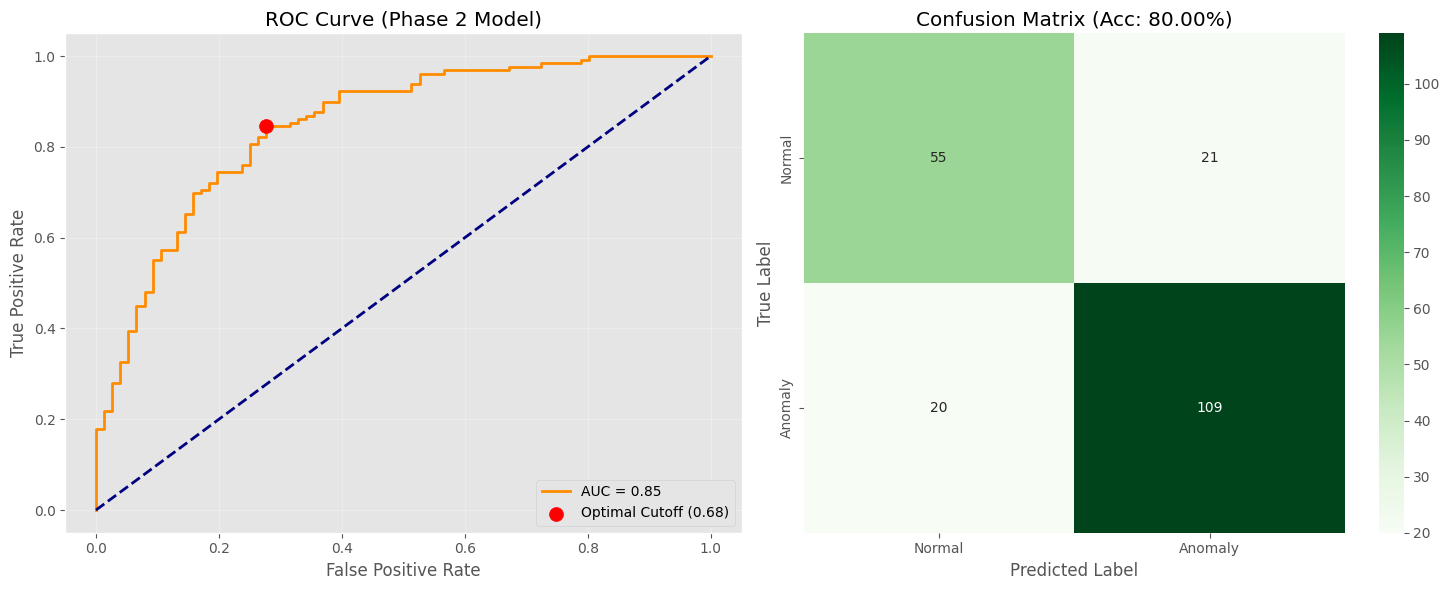

✅ Phase 2 Model Saved to Drive: /content/drive/MyDrive/smarthome_phase2_augmented.pth


In [ ]:
# --- CELL 14: FINAL COMPARATIVE EVALUATION (PHASE 2) ---
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import roc_curve, auc, roc_auc_score, accuracy_score, confusion_matrix, classification_report
import torch
from torch.utils.data import DataLoader, TensorDataset

# 1. Select the Best Model Available
if 'model_aug' in globals():
    print("🚀 EVALUATING: Phase 2 Model (Augmented Data)")
    final_model = model_aug
elif 'model' in globals():
    print("⚠️ EVALUATING: Phase 1 Model (Standard Data)")
    final_model = model
else:
    raise ValueError("No model found! Please run training first.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
final_model.eval()

# 2. Prepare Data
if 'test_loader' not in locals():
    test_loader = DataLoader(TensorDataset(test_X.to(device), test_y.to(device)), batch_size=32, shuffle=False)

# 3. Generate Predictions
y_true, y_pred = [], []
print("Generating predictions...")

with torch.no_grad():
    for feats, labels in test_loader:
        outputs = final_model(feats).squeeze()
        y_true.extend(labels.squeeze().cpu().numpy())
        y_pred.extend(outputs.cpu().numpy())

# 4. Calculate Stats
auc_score = roc_auc_score(y_true, y_pred)
fpr, tpr, thresholds = roc_curve(y_true, y_pred)
best_thresh_idx = np.argmax(tpr - fpr)
best_thresh = thresholds[best_thresh_idx]

# Apply threshold
final_preds = [1 if p >= best_thresh else 0 for p in y_pred]
final_acc = accuracy_score(y_true, final_preds)

# --- REPORTING ---
print("\n" + "="*40)
print(f"🏆 PHASE 2 TEST RESULTS")
print("="*40)
print(f"1. FINAL ACCURACY:    {final_acc*100:.2f}%")
print(f"2. AUC SCORE:         {auc_score:.4f}")
print(f"3. OPTIMAL THRESHOLD: {best_thresh:.4f}")
print("-" * 40)
print(classification_report(y_true, final_preds, target_names=['Normal', 'Anomaly']))
print("="*40)

# --- PLOTTING ---
plt.figure(figsize=(15, 6))

# Plot A: ROC Curve
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {auc_score:.2f}')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.scatter(fpr[best_thresh_idx], tpr[best_thresh_idx], c='red', s=100, label=f'Optimal Cutoff ({best_thresh:.2f})', zorder=10)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Phase 2 Model)')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

# Plot B: Confusion Matrix
plt.subplot(1, 2, 2)
cm = confusion_matrix(y_true, final_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal', 'Anomaly'], yticklabels=['Normal', 'Anomaly'])
plt.title(f'Confusion Matrix (Acc: {final_acc*100:.2f}%)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

plt.tight_layout()
plt.show()

# Save the Best Model
save_path = '/content/drive/MyDrive/smarthome_phase2_augmented.pth'
torch.save(final_model.state_dict(), save_path)
print(f"✅ Phase 2 Model Saved to Drive: {save_path}")